## Latent variable with continuous states extraction


## Setup

In [ ]:
from google.colab import drive
drive.mount('/content/gdrive')

# import custom helper functions
!cp "/content/gdrive/MyDrive/Colab Notebooks/latent/src/model_utils.py" .
!cp "/content/gdrive/MyDrive/Colab Notebooks/latent/src/feature_utils.py" .
!cp "/content/gdrive/MyDrive/Colab Notebooks/latent/src/evaluation_utils.py" .

!rm -rf DL4CM # clear up dir if any
!git clone https://github.com/ti55987/DL4CM.git

Mounted at /content/gdrive
Cloning into 'DL4CM'...
remote: Enumerating objects: 219, done.
remote: Counting objects: 100% (219/219), done.
remote: Compressing objects: 100% (163/163), done.
remote: Total 219 (delta 121), reused 146 (delta 48), pack-reused 0 (from 0)
Receiving objects: 100% (219/219), 4.99 MiB | 32.55 MiB/s, done.
Resolving deltas: 100% (121/121), done.


In [ ]:
import time

import numpy as np
from numpy import sqrt, argmax

import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.utils import shuffle
from datetime import datetime
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    mean_squared_error,
    accuracy_score,
    balanced_accuracy_score,
    r2_score,
)

from model_utils import (
    Mode,
    normalize_train_labels,
    normalize_val_labels,
    set_seed,
    get_labels,
)

from feature_utils import (
    get_onehot_features,
    get_latent_labels,
)

from evaluation_utils import (
    plot_time_series,
    get_all_agent_accuracy,
    get_all_agents_scores,
    get_regression_rmse,
    add_corr_scores,
    get_all_agents_rmse,
    derive_rpe_from_q,
)

In [ ]:
%cd DL4CM

from utils.feature_utils import (
    get_iter_acc_without_switches,
    get_iter_acc_with_switches,
    extract_features_blockless,
)

/content/DL4CM


## Constants

In [ ]:
DRIVE_DIR = '/content/gdrive/Shareddrives/DLCCM/blocks'
task = 'RLF-6S3A'
DATA_DIR = f'/content/gdrive/MyDrive/Colab Notebooks/data/{task}'
RESULT_DIR = f'{DRIVE_DIR}/results/{task}'
N_TRAIN_AGENT, N_TEST_AGENT = 18000, 500
num_blocks = 12
num_trials_per_block = 6*13
beta_multiplier = 20

suffix = 'rlf' #'2ParamRL_no_switch_phi01_b20_seq' #'''2ParamRL_no_switch' #2alpha_no_switch
prefix = f'rand500_st11_{N_TRAIN_AGENT}a_{num_blocks}b_{num_trials_per_block}t_{suffix}'
test_suffix = suffix#'2ParamRL_no_switch_phi01_b20_seq' #2alpha_switch' #''
#training_data = pd.read_csv(f'{DATA_DIR}/{prefix}.csv')
test_data = pd.read_csv(f'{DATA_DIR}/rand500_st11_{N_TEST_AGENT}a_{num_blocks}b_{num_trials_per_block}t_{test_suffix}.csv')

In [ ]:
# @title Helpers
# adding stim_iter doesn't help
all_feature_list = [
    # ['rewards'],
    # ['rewards', 'delay_since_last_stimuli'] ,
    # ['rewards', 'delay_since_last_stimuli', 'actions'] ,
    ['rewards', 'delay_since_last_stimuli', 'actions',  'prev_action'] ,
    ['rewards', 'delay_since_last_stimuli', 'actions', 'prev_action', 'isswitch', 'stimuli'] ,
]

def get_features_labels(data, feature_list):
  n_block = data['block_no'].nunique()
  n_trial = data['trials'].nunique()

  n_agent = data['agentid'].nunique()
  qv = np.array(data['rewards'] - data['rpe_history'])
  labels = qv.astype(np.float32).reshape((n_agent, n_block*n_trial))

  features = extract_features_blockless(td_iter, feature_list, [])
  print(features.shape)
  return features, labels

def save_data(model, history, identifier):
  result = pd.DataFrame(history.history)
  ax = sns.lineplot(result)
  ax.set_xlabel('epochs')
  ax.set_ylabel('loss')

  ax.figure.savefig(f'{RESULT_DIR}/lasenet_{identifier}.png')
  model.save(f'{RESULT_DIR}/lasenet_{identifier}_model.keras')

def evaluate_on_test(model, test_iter, feature_list):
  test_features = extract_features_blockless(test_iter, feature_list, [])

  num_test_agents = test_iter['agentid'].nunique()
  n_trial = test_iter['trials'].nunique()
  n_block = test_iter['block_no'].nunique()
  qv = np.array(test_iter['rewards'] - test_iter['rpe_history'])
  test_labels = qv.astype(np.float32).reshape((num_test_agents, n_block*n_trial))

  output_tokens = model.predict(test_features)
  rewards = test_data['rewards'].to_numpy().astype(np.int64).reshape((num_test_agents, n_trial*n_block))
  # RPE
  true_cont = rewards - test_labels
  pred_q = output_tokens.reshape(num_test_agents,  n_trial*n_block)
  pred_cont = rewards - pred_q
  df = pd.DataFrame({
      'true_rpe': true_cont.ravel(), 'pred_rpe': pred_cont.ravel(),
      'true_q': test_labels.ravel(), 'pred_q': pred_q.ravel()})

  return true_cont, pred_cont, df


## Process Data

In [ ]:
# @title concat multiple train files

list_of_train_files = [
    f"rand500_st11_18000a_{num_blocks}b_{num_trials_per_block}t_{suffix}",
    f"rand_500seqs_9000a_{num_blocks}b_{num_trials_per_block}t_{suffix}",
]

training_data = None
for f in list_of_train_files:
  data = pd.read_csv(f'{DATA_DIR}/{f}.csv')
  n_agent = len(data['agentid'].unique())
  if training_data is not None:
    data['agentid'] = data['agentid'] + training_data.agentid.max() + 1
    training_data = pd.concat([training_data, data])
  else:
    training_data = data

  del data # save memory

len(training_data.agentid.unique())

27000

In [ ]:
# @title iteration extraction

# fixed seed
sampled_agents = np.random.choice(training_data['agentid'].unique(), size=500, replace=False)
# Filter your dataframe to only include those agents
data = training_data[training_data['agentid'].isin(sampled_agents)].copy()
N_TRAIN_AGENT = data.agentid.nunique()
has_switches = (data.isswitch.nunique() == 2)
td_iter = data.copy() #get_iter_acc_with_switches(data) if has_switches else get_iter_acc_without_switches(data)

if has_switches:
  td_iter.loc[td_iter.trials == 0, 'isswitch'] = 1
else:
  td_iter['isswitch'] = td_iter['trials'].apply(lambda x: 1 if x == 0 else 0)

td_iter['prev_action'] = data.groupby(['agentid', 'block_no'])['actions'].shift(1).fillna(-1).astype(int).to_list()
td_iter['delay_since_last_stimuli'] = data['delay_since_last_stimuli'].to_list()

has_switches = (test_data.isswitch.nunique() == 2)
test_iter = test_data.copy()
test_iter['isswitch'] = test_iter['trials'].apply(lambda x: 1 if x == 0 else 0)
test_iter['prev_action'] = test_data.groupby(['agentid', 'block_no'])['actions'].shift(1).fillna(-1).astype(int).to_list()
test_iter['delay_since_last_stimuli'] = test_data['delay_since_last_stimuli'].to_list()

In [ ]:
#@title one set of features

features, train_labels = get_features_labels(td_iter, all_feature_list[-1])

X_train, X_test, qv_train, qv_test = train_test_split(features, train_labels, test_size=0.1, random_state=33)
# val_features, normalized_val_labels = shuffle(val_features, normalized_val_labels, random_state=0)
# print(train_features.shape, val_features.shape, normalized_val_labels.shape)
print(
    X_train.shape,
    X_test.shape,
    qv_train.shape,
    qv_test.shape,
)

## Model Training

In [ ]:
# @title Model definition

from tensorflow.keras import layers
from keras.callbacks import EarlyStopping, ReduceLROnPlateau

from tensorflow.keras.layers import (
    Dense,
    Dropout,
    LSTM,
    Bidirectional,
    GRU,
    Concatenate,
)
from tensorflow import keras
from tensorflow.keras.optimizers import Adam, SGD

tf.keras.utils.set_random_seed(11)
tf.config.experimental.enable_op_determinism()

RNN = GRU
is_bidirection = True
op_loss = 'mse'
#edl.layers.DenseNormalGamma(1), # Evidential distribution!
def create_gru_model(
    feature_dim: int, units: int=70, dropout: float=0.2, dropout1: float=0.2, dropout2: float=0.1, learning_rate: float=3e-4):
    activation_func = 'relu'

    encoder_inputs = layers.Input(shape=(None, feature_dim))
    encoder = Bidirectional(RNN(units, return_state=False, return_sequences=True))
    #encoder_outputs, forward_h, backward_h = encoder(encoder_inputs)
    encoder_outputs = encoder(encoder_inputs)
    encoder_outputs = Dropout(dropout)(encoder_outputs) #Dropout(dropout)(encoder_outputs)

    # Dense layers
    outputs = Dense(int(units/2), activation='relu')(encoder_outputs)
    outputs = Dropout(dropout1)(outputs)
    outputs = Dense(int(units/4), activation='relu')(outputs)
    outputs = Dropout(dropout2)(outputs)
    outputs = Dense(output_dim, activation='linear')(outputs)

    best_model = keras.Model(encoder_inputs, outputs)

    optimizer = Adam(learning_rate=learning_rate)
    best_model.compile(loss=op_loss, optimizer=optimizer, metrics=[tf.keras.metrics.RootMeanSquaredError()])
    return best_model

def create_multiple_loss_model(
    feature_dim: int,
    units: int = 70,
    dropout: float = 0.2,
    dropout1: float = 0.2,
    dropout2: float = 0.1,
    learning_rate: float = 3e-4,
):
    activation_func = "relu"
    # Bidirectional
    encoder_inputs = layers.Input(shape=(None, feature_dim))
    if is_bidirection:
      encoder = Bidirectional(RNN(units, return_state=False, return_sequences=True))
    else:
      encoder = RNN(units, return_state=False, return_sequences=True)

    encoder_outputs = encoder(encoder_inputs)
    encoder_outputs = Dropout(dropout)(encoder_outputs) #Dropout(dropout)(encoder_outputs)

    d_outputs_1 = Dense(int(units / 2), activation=activation_func)(encoder_outputs)
    d_outputs_1 = Dropout(dropout1)(d_outputs_1)
    d_outputs_1 = Dense(int(units / 4), activation=activation_func)(d_outputs_1)
    d_outputs_1 = Dropout(dropout2)(d_outputs_1)

    k_outputs = Dense(cue_output_dim, activation="softmax", name="chosen_cue")(d_outputs_1)
    # Dense layers
    linear_outputs = Dense(output_dim, activation="linear", name="q_values")(
        d_outputs_1
    )

    model = keras.Model(inputs=encoder_inputs, outputs=[k_outputs, linear_outputs])
    optimizer = Adam(learning_rate=learning_rate)
    model.compile(
        loss={
            "chosen_cue": "categorical_crossentropy",
            "q_values": "mse",
        },
        loss_weights={"chosen_cue": 0.2, "q_values": 1},
        optimizer=optimizer,
    )
    return model



def get_multiple_loss_gru_model(parms):
    return create_multiple_loss_model(
        parms['input_y'],
        parms['units'],
        parms['dropout'],
        parms['dropout1'],
        parms['dropout2'],
        parms['learning_rate'])

def create_model(
    feature_dim: int,
    discrete_output_dim: int,
    continuous_output_dim: int,
    units: int = 70,
    dropout: float = 0.2,
    dropout1: float = 0.2,
    dropout2: float = 0.1,
):
    activation_func = "relu"
    # Bidirectional
    encoder_inputs = layers.Input(shape=(None, feature_dim))
    # Modified GRU with reset_after=True for CuDNN compatibility
    gru_layer = RNN(
        units,
        return_state=False,
        return_sequences=True,
        #reset_after=True,
    )
    encoder = Bidirectional(gru_layer)
    encoder_outputs = encoder(encoder_inputs)
    #encoder_outputs, _, _ = encoder(encoder_inputs)
    encoder_outputs = Dropout(dropout)(encoder_outputs)

    d_outputs_1 = Dense(int(units / 2), activation=activation_func)(encoder_outputs)
    d_outputs_1 = Dropout(dropout1)(d_outputs_1)
    d_outputs_1 = Dense(int(units / 4), activation=activation_func)(d_outputs_1)
    d_outputs_1 = Dropout(dropout2)(d_outputs_1)

    outputs = []
    if discrete_output_dim > 0:
        k_outputs = Dense(discrete_output_dim, activation="softmax", name="discrete_latent")(d_outputs_1)
        outputs.append(k_outputs)

    if continuous_output_dim > 0:
        linear_outputs = Dense(continuous_output_dim, activation="linear", name="continuous_latent")(
            d_outputs_1
        )
        outputs.append(linear_outputs)

    return keras.Model(inputs=encoder_inputs, outputs=outputs)

def get_gru_model(parms):
    return create_gru_model(
        parms['feature_dim'], parms['units'], parms['dropout'], parms['dropout1'], parms['dropout2'], parms['learning_rate'])

Random seed set as 123
r-d-a-p
(500, 936, 4)
(500, 936)
(450, 936, 4) (50, 936, 4) (450, 936) (50, 936)
RLF-6S3A_r-d-a-p_A500_936t_B128_U256_D0.097_D0.013_D0.011_0.000696
Epoch 1/600
4/4 - 3s - 737ms/step - loss: 0.1035 - root_mean_squared_error: 0.3218 - val_loss: 0.0431 - val_root_mean_squared_error: 0.2077
Epoch 2/600
4/4 - 0s - 99ms/step - loss: 0.0513 - root_mean_squared_error: 0.2264 - val_loss: 0.0314 - val_root_mean_squared_error: 0.1773
Epoch 3/600
4/4 - 0s - 97ms/step - loss: 0.0447 - root_mean_squared_error: 0.2115 - val_loss: 0.0399 - val_root_mean_squared_error: 0.1999
Epoch 4/600
4/4 - 0s - 99ms/step - loss: 0.0429 - root_mean_squared_error: 0.2071 - val_loss: 0.0269 - val_root_mean_squared_error: 0.1641
Epoch 5/600
4/4 - 0s - 98ms/step - loss: 0.0376 - root_mean_squared_error: 0.1940 - val_loss: 0.0241 - val_root_mean_squared_error: 0.1553
Epoch 6/600
4/4 - 0s - 97ms/step - loss: 0.0359 - root_mean_squared_error: 0.1893 - val_loss: 0.0267 - val_root_mean_squared_error: 0

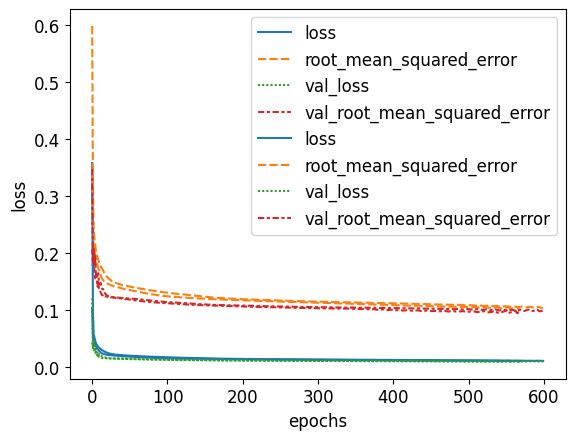

In [ ]:
import time

seed = 123
set_seed(seed)

for feature_list in all_feature_list:
    feature_string = "-".join([item[0] for item in feature_list])
    print(feature_string)
    # Extract features
    features, train_labels = get_features_labels(td_iter, feature_list)
    output_dim = train_labels.shape[-1] if train_labels.ndim > 2 else 1
    print(train_labels.shape)

    X_train, X_test, qv_train, qv_test = train_test_split(features, train_labels, test_size=0.1, random_state=33)
    print(
        X_train.shape,
        X_test.shape,
        qv_train.shape,
        qv_test.shape,
    )

    # Model preparation
    batch_size = 128
    units =  256 #193 #512 #
    dropout = 0.097 #0.07 #0.25 #
    dropout1 = 0.013 #0.053 #0.05 #
    dropout2 = 0.011 #0.014 #0.01 #
    learning_rate = 0.000696 #3e-4

    curr = time.strftime("%H%M%S")
    prefix = task+'_'+feature_string
    n_agents, n_trial = features.shape[0], features.shape[1]

    identifier = f'{prefix}_A{n_agents}_{n_trial}t_B{batch_size}_U{units}_D{dropout}_D{dropout1}_D{dropout2}_{learning_rate}'

    best_model = create_gru_model(
        feature_dim=X_train.shape[-1],
        # continuous_output_dim=1,
        # discrete_output_dim=0,
        units=units,
        dropout=dropout,
        dropout1=dropout1,
        dropout2=dropout2,
    )

    print(identifier)
    callbacks = [EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)]
    start = time.time()
    history = best_model.fit(
      X_train,
      y=qv_train,
      batch_size=batch_size,
      epochs=600,
      verbose=2,
      callbacks=callbacks,
      validation_data=(X_test, qv_test),
    )

    end = time.time()
    save_data(best_model, history, identifier)

    # Extract test features
    true_cont, pred_cont, df = evaluate_on_test(best_model, test_iter, feature_list)
    #test_features = extract_features_blockless(test_iter, feature_list

    df.to_csv(f'{RESULT_DIR}/{identifier}_prediction.csv')

## Model Evaluation

In [ ]:
%matplotlib inline
import warnings; warnings.simplefilter('ignore')  # hide warnings

feature_list = all_feature_list[-1]
test_features, test_labels = get_features_labels(test_iter, feature_list)
print(test_features.shape, test_labels.shape)

#  #zou_A10000_500t_B128_U193_0.0003_D0.07_D0.053_D0.014_model
# model_name = 'lasenet_rand_500seqs_RLF-6S3A_r-d-a-i-s_A9000_936t_B128_U256_D0.097_D0.013_D0.011_0.000696_model.keras'
# # 'lasenet_s123_RLF-6S3A_r-d-a-i-s_A18000_936t_B128_U256_D0.097_D0.013_D0.011_0.000696_model.keras'
# best_model = tf.keras.models.load_model(f'{RESULT_DIR}/{model_name}')
output_tokens = best_model.predict(test_features)

true_cont, pred_cont, df = evaluate_on_test(best_model, test_iter, feature_list)

(500, 936, 6)
(500, 936, 6) (500, 936)
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step


In [ ]:
# @title Save the results
#identifier = model_name.removesuffix('_model.keras')
df.to_csv(f'{RESULT_DIR}/rand500_st11_prediction.csv')

### RPE

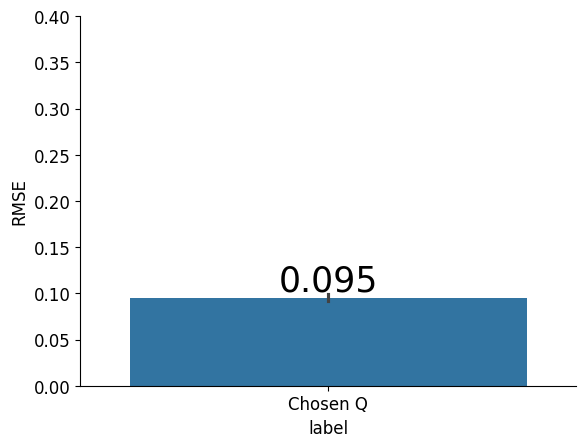

In [ ]:
# @title Continous latent summary - bar plot
from sklearn.metrics import root_mean_squared_error

def get_all_agents_rmse(y_true, y_pred, squared: bool=False):
  all_mse = []
  for a, pred in enumerate(y_pred):
    mse = root_mean_squared_error(y_true[a], pred)
    all_mse.append(mse)

  return all_mse

plt.rcParams.update({"font.size": 12})
result = {'rmse': [], 'label': []}
all_mse = get_all_agents_rmse(true_cont, pred_cont)
result['rmse'].extend(all_mse)
label = 'Chosen Q'
result['label'].extend(len(all_mse)*[label])

b = sns.barplot(result, x="label", y="rmse")
b.set_ylabel('RMSE')
b.set(ylim=(0, 0.4))

for i in b.containers:
    b.bar_label(i, fmt='%.3f', size=25, color='black')

sns.despine()

In [ ]:
# @title time series plot for RPE

from model_utils import get_labels

def find_value_changes(arr):
    # Use np.diff to calculate differences between consecutive elements
    diff = np.diff(arr)
    diff[diff != 0] = 1
    # Add 1 to the indices to account for the shift caused by np.diff
    return diff

def _get_labels(data, label_names):
    name_to_labels = {}
    for l in label_names:
      name_to_labels[l] = data.groupby('agentid')[l].agg(['mean']).to_numpy()

    return name_to_labels

nrows = 3
fig, axes = plt.subplots(nrows=nrows, ncols=2, figsize=(2*10, nrows*2), sharey=True, sharex=True)

max_trial = num_trials_per_block*2
axes = plot_time_series(axes, true_cont, pred_cont, max_trial)
# N_VAL_AGENT = true_cont.shape[0]
# # add parameters to title and switch lines
name_to_labels = get_labels(test_data, Mode.PRL2)

for idx, ax in enumerate(axes.flat):
  title = ''
  for k, v in name_to_labels.items():
    val = round(v[idx][0], 2)
    title = f'{title}{k}:{val} '

  ax.set_title(title, size=14)
  ax.set_ylabel('RPE')
  ax.set_yticks([-1, 0, 1])
  #switched_trials = np.argwhere(isswitch[idx])
  ax.vlines(x = np.arange(0, max_trial, num_trials_per_block), ymin = -1, ymax = 1, color='red', linestyles='--')

sns.despine()

In [ ]:
num_test_agents = test_data['agentid'].nunique()
n_trial = test_data['trials'].nunique()
n_block = test_data['block_no'].nunique()
reward = test_data['rewards'].to_numpy().astype(np.int64).reshape((num_test_agents, n_trial*n_block))
print(reward.shape)

nrows = 2
fig, axes = plt.subplots(nrows=nrows, ncols=2, figsize=(2*10, nrows*2), sharey=True, sharex=True)
# # add parameters to title and switch lines
name_to_labels = get_labels(test_data, Mode.PRL2)
# Assuming name_to_labels['alpha'] is a NumPy array
alpha_values = name_to_labels['alpha'].ravel()
beta_values = name_to_labels['beta'].ravel()
# Find indices where values are greater than 0.65
indices = np.where((alpha_values > 0.65)) #np.where((alpha_values > 0.78) | (alpha_values < 0.23)) #

true_q = reward-true_cont
pred_q = reward-pred_cont
max_trial = n_trial*2
axes = plot_time_series(axes, true_q[indices], pred_q[indices], max_trial)

name_to_labels = {'alpha': alpha_values[indices], 'beta': beta_values[indices]}
for idx, ax in enumerate(axes.flat):
  title = ''
  for k, v in name_to_labels.items():
    val = round(v[idx], 2) #round(v[idx][0], 2)
    title = f'{title}{k}:{val} '

  ax.set_title(title, size=14)
  ax.set_yticks([0, 0.5, 1])
  ax.set_ylabel('chosen Q value')
  #switched_trials = np.argwhere(isswitch[idx])
  ax.vlines(x = np.arange(0, max_trial, n_trial), ymin = 0, ymax = 1, color='red', linestyles='--')

sns.despine()

In [ ]:
# @title RMSE of RPE against parameters
all_mse = get_all_agents_rmse(true_rpe, pred_rpe, False)
name_to_labels = get_labels(test_data, mode.PRL4)
train_name_to_labels = get_labels(data, mode.PRL4)

n_cols = len(name_to_labels)
fig, axes = plt.subplots(nrows=1, ncols=n_cols, figsize=(3*n_cols, 3), sharey=True, sharex=False)
fig.suptitle('ANN')
for idx, p in enumerate(name_to_labels.keys()):
  p_data = list(name_to_labels[p].ravel())

  result = pd.DataFrame({p: p_data, 'rmse': all_mse})
  ax2 = axes.flat[idx].twinx()
  ax = sns.regplot(
      data=result, x=p, y='rmse', line_kws=dict(color="#f73e40"), color='grey', ax=axes.flat[idx], scatter_kws={'s':12},
  )
  c = sns.color_palette()[0]
  sns.kdeplot(train_name_to_labels[p], legend=False, color=c, ax=ax2)
  ax2.set_ylabel('Training Data Density', color=c)
  ax2.tick_params(axis='y', labelsize=8, labelcolor=c)
  #ax = add_corr_scores(ax, p_data, all_mse)

  ax.set_title(f'{p} vs rmse', fontsize=12)

fig.tight_layout()

### Discrete states confusion matrix

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

if mode == Mode.PRL_foraging_dynamic:
  threshold = 0.5
  pred_cue = (output_tokens[0][:, :, 1] >= threshold).astype(int)
else:
  pred_cue = np.argmax(np.array(output_tokens[0]), axis=2)

fig, ax = plt.subplots(figsize=(12, 12))
true_latent = test_data[latent_key].to_numpy().astype(int).reshape((num_test_agents, n_trial))
disp = ConfusionMatrixDisplay.from_predictions(
    true_latent.ravel(),
    pred_cue.ravel(),
    cmap=plt.cm.Blues,
    colorbar=False,
    text_kw={'size': 10},
    values_format='.2f',
    ax=ax,
    normalize='true')
# Set the fixed color bar range
disp.im_.set_clim(0, 1)
#disp.ax_.set_title(f'ANN trained w {n_agents} agents {n_trial} trials')
print(true_latent.shape, pred_cue.shape)
disp.ax_.tick_params(axis='both', which='major', labelsize=8, rotation=20)
all_scores = get_all_agents_scores(true_latent, pred_cue, accuracy_score)
np.mean(all_scores)

In [ ]:
# @title time series plot for state /chosen cues
nrows = 1
fig, axes = plt.subplots(nrows=nrows, ncols=4, figsize=(4 * 4, nrows * 2), sharey=True, sharex=True)
predicted_state = np.argmax(output_tokens[0], axis=2)
task_set = get_latent_labels(test_data, ['state'])
true_latent = test_data[latent_key].to_numpy().reshape(num_test_agents, n_trial)
max_trial = 100

for idx, ax in enumerate(axes.flat):
  result = pd.DataFrame(
      {
          "Groud Truth": true_latent[idx][:max_trial],
          "LaseNet": predicted_state[idx][:max_trial],
          "TS": task_set[idx][:max_trial],

      }
  )
  markers = {"Groud Truth": "X", "TS": "v", "LaseNet": "o"}
  show_legend = True if idx == 0 else False
  plot_ = sns.scatterplot(result, markers=markers, ax=ax, legend=show_legend, s=50, alpha=0.6) #lineplot
  if show_legend:
    sns.move_legend(
      ax, "lower center",
      bbox_to_anchor=(1, 1.1), ncol=3, title=None, frameon=False,
    )

  ax.set_xlabel('trial #')
  ax.set_ylabel('state #')
  ax.set_title(f'agent {idx}', fontsize=10)
  sns.despine()

## Grid Search

In [ ]:
# For grid search
!pip install --upgrade keras-hypetune
!pip install -q -U keras-tuner

In [ ]:
from hyperopt import hp, Trials
from kerashypetune import KerasBayesianSearch


param_grid = {
  'feature_dim': features.shape[-1],
  'units': hp.choice('units', [256, 128, 512]),
  'learning_rate': hp.loguniform('learning_rate', np.log(3e-4), np.log(3e-2)),
  'dropout': hp.uniform('dropout', .015, .25),
  'dropout1': hp.uniform('dropout1', .01, .2),
  'dropout2': hp.uniform('dropout2', .01, .2),
  'epochs': 35,
  'batch_size': hp.choice('batch_size', [128, 256]),
}

model_func = get_gru_model
output_dim = train_labels.shape[-1] if train_labels.ndim > 2 else 1
kbs = KerasBayesianSearch(
    model_func, param_grid, monitor='val_loss', greater_is_better=False, n_iter=10, sampling_seed=33)
callbacks = [EarlyStopping(monitor='val_loss', patience=35)]

kbs.search(
  x=X_train,
  y=qv_train,
  trials=Trials(),
  validation_data=(X_test, qv_test),
  callbacks=callbacks,
)

print(kbs.best_params)
print(kbs.scores)

In [ ]:
from kerashypetune import KerasGridSearch

# Set up hyperparameters to test
param_grid = {
  'input_y': features.shape[-1],
  'units': [512],
  'learning_rate': 3e-3, #hp.loguniform('learning_rate', np.log(3e-4), np.log(3e-2)),
  'dropout': [.05, .25],
  'dropout1': [.01, .05, .1],
  'dropout2': [.01, .02, .05],
  'epochs': 25,
  'batch_size': [128],
}

callbacks = [EarlyStopping(monitor='val_loss', patience=35)]
kgs = KerasGridSearch(get_multiple_loss_gru_model, param_grid, monitor='val_loss', greater_is_better=False)
kgs.search(
    x=X_train,
    y={'chosen_cue': chosen_cue_train, 'q_values': qv_train},
    validation_data=(X_test, {'chosen_cue': chosen_cue_test, 'q_values': qv_test}),
    callbacks=callbacks)
print(kgs.best_params)
print(kgs.scores)

In [ ]:
from kerashypetune import KerasBayesianSearch
from hyperopt import hp, Trials

model_func = get_multiple_loss_gru_model
param_grid = {
  'input_y': features.shape[-1],
  'units': 36 + hp.randint('units', 200),
  'learning_rate': 3e-4, #hp.loguniform('learning_rate', np.log(3e-4), np.log(3e-2)),
  'dropout': hp.uniform('dropout', .05, .25),
  'dropout1': hp.uniform('dropout1', .01, .1),
  'dropout2': hp.uniform('dropout2', .01, .05),
  'epochs': 25,
  'batch_size': 256,
}

kbs = KerasBayesianSearch(model_func, param_grid, monitor='val_loss', greater_is_better=False, n_iter=10, sampling_seed=66)
callbacks = [EarlyStopping(monitor='val_loss', patience=10)]

kbs.search(
    x=X_train,
    y={'chosen_cue': chosen_cue_train, 'q_values': qv_train},
    trials=Trials(),
    validation_data=(X_test, {'chosen_cue': chosen_cue_test, 'q_values': qv_test}),
    callbacks=callbacks)

print(kbs.best_params)
print(kbs.scores)